# Replay one experimental game

This notebook replays one Choi 2020 game and shows:

- the replay setup in separate stages
- the actions printed per step
- the directed ownership graph after each recorded state
- the density evolution across the replay


## Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from netgraph import Graph

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.data.choi_2020 import (
    build_replay_simulator,
    list_choi_2020_configs
)
from network_creation.observers.action_print_observer import ActionPrintObserver
from network_creation.observers.density_observer import DensityObserver
from network_creation.observers.state_history_observer import StateHistoryObserver


In [2]:
def build_circle_layout(n_nodes):
    angles = np.linspace(0, 2 * np.pi, n_nodes, endpoint=False)
    return {
        node_id: (float(np.cos(angle)), float(np.sin(angle)))
        for node_id, angle in enumerate(angles)
    }


def build_ownership_graph(ownership_matrix):
    graph = nx.DiGraph()
    n_nodes = ownership_matrix.shape[0]
    graph.add_nodes_from(range(n_nodes))
    for source_node_id, target_node_id in zip(*np.nonzero(ownership_matrix), strict=False):
        graph.add_edge(int(source_node_id), int(target_node_id))
    return graph


def compute_subplot_shape(n_plots, max_cols=4):
    n_cols = min(max_cols, max(1, int(np.ceil(np.sqrt(n_plots)))))
    n_rows = int(np.ceil(n_plots / n_cols))
    return n_rows, n_cols


In [3]:
import pandas as pd
df = pd.read_csv("/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv")
df[(df["session"]==1) & (df["round"]==2) & (df["grp"]==1) & (df["id_grp"]==3)].head(20)

,id,id_subj,time,session,id_grp,grp,round,period,effort,links
1621,1622,27,7,1,3,1,2,1,NaN,[5]
1633,1634,27,8,1,3,1,2,1,NaN,"[5,8]"
1668,1669,27,14,1,3,1,2,1,NaN,[5]
1673,1674,27,14,1,3,1,2,1,NaN,"[5,9]"
1681,1682,27,15,1,3,1,2,1,NaN,[5]
1686,1687,27,16,1,3,1,2,1,NaN,"[5,10]"
1699,1700,27,18,1,3,1,2,1,NaN,[5]
1702,1703,27,19,1,3,1,2,1,NaN,[]
1712,1713,27,20,1,3,1,2,1,NaN,[8]
1723,1724,27,22,1,3,1,2,1,NaN,[]


## Replay data


In [4]:
data_root = project_root / "data/choi_2020/raw"
available_configs = list_choi_2020_configs(data_root)
available_configs[:5]


(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=3, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=4, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=5, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=6, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')))

## Observer settings


In [5]:
action_printer = ActionPrintObserver(observation_frequency=1, print_empty_steps=False)
density_observer = DensityObserver(observation_frequency=1)
state_history_observer = StateHistoryObserver(observation_frequency=1)

(
    action_printer.__class__.__name__,
    density_observer.__class__.__name__,
    state_history_observer.__class__.__name__,
)


('ActionPrintObserver', 'DensityObserver', 'StateHistoryObserver')

## Build the replay simulator


In [6]:
config = available_configs[0]
config

Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv'))

In [7]:
simulator = build_replay_simulator(
    config=config,
    observers=[action_printer, density_observer, state_history_observer],
)

fixed_layout = build_circle_layout(simulator.n_agents)
(simulator.mode, simulator.max_steps, simulator.n_agents)


(<SchedulingMode.SIMULTANEOUS: 'SIMULTANEOUS'>, 359, 10)

## Run the replay


In [8]:
simulator.run_episode()

print("current_step:", simulator.current_step)
print("last_modified_step:", simulator.last_modified_step)



step 6
  8: ADD->2

step 7
  2: ADD->4
  3: ADD->5
  6: ADD->4
  8: ADD->3, ADD->4

step 8
  1: ADD->5
  2: ADD->7

step 9
  5: ADD->7
  7: ADD->0
  8: ADD->6
  9: ADD->8

step 10
  8: ADD->0

step 11
  4: ADD->8
  6: DELETE->4

step 12
  1: ADD->4

step 13
  1: DELETE->5
  7: DELETE->0

step 14
  2: DELETE->7, ADD->8

step 15
  2: DELETE->8
  5: ADD->8

step 16
  2: ADD->9

step 17
  5: DELETE->7

step 18
  2: DELETE->9
  3: DELETE->5
  8: ADD->7

step 19
  1: ADD->8
  2: DELETE->4

step 20
  1: DELETE->4
  2: ADD->7

step 22
  2: DELETE->7

step 23
  2: ADD->6

step 24
  9: ADD->4, DELETE->8

step 26
  2: DELETE->6

step 28
  8: ADD->9

step 31
  3: ADD->7
  5: ADD->9

step 32
  3: DELETE->7
  5: DELETE->8

step 34
  5: ADD->8

step 35
  3: ADD->8
  5: DELETE->9

step 36
  2: ADD->5

step 37
  2: DELETE->5

step 39
  2: ADD->1
  3: DELETE->8

step 40
  2: DELETE->1

step 41
  2: ADD->0
  8: DELETE->4

step 42
  2: DELETE->0

step 43
  2: ADD->7
  5: ADD->2

step 44
  2: DELETE->7
  

## Directed ownership graph after each recorded state


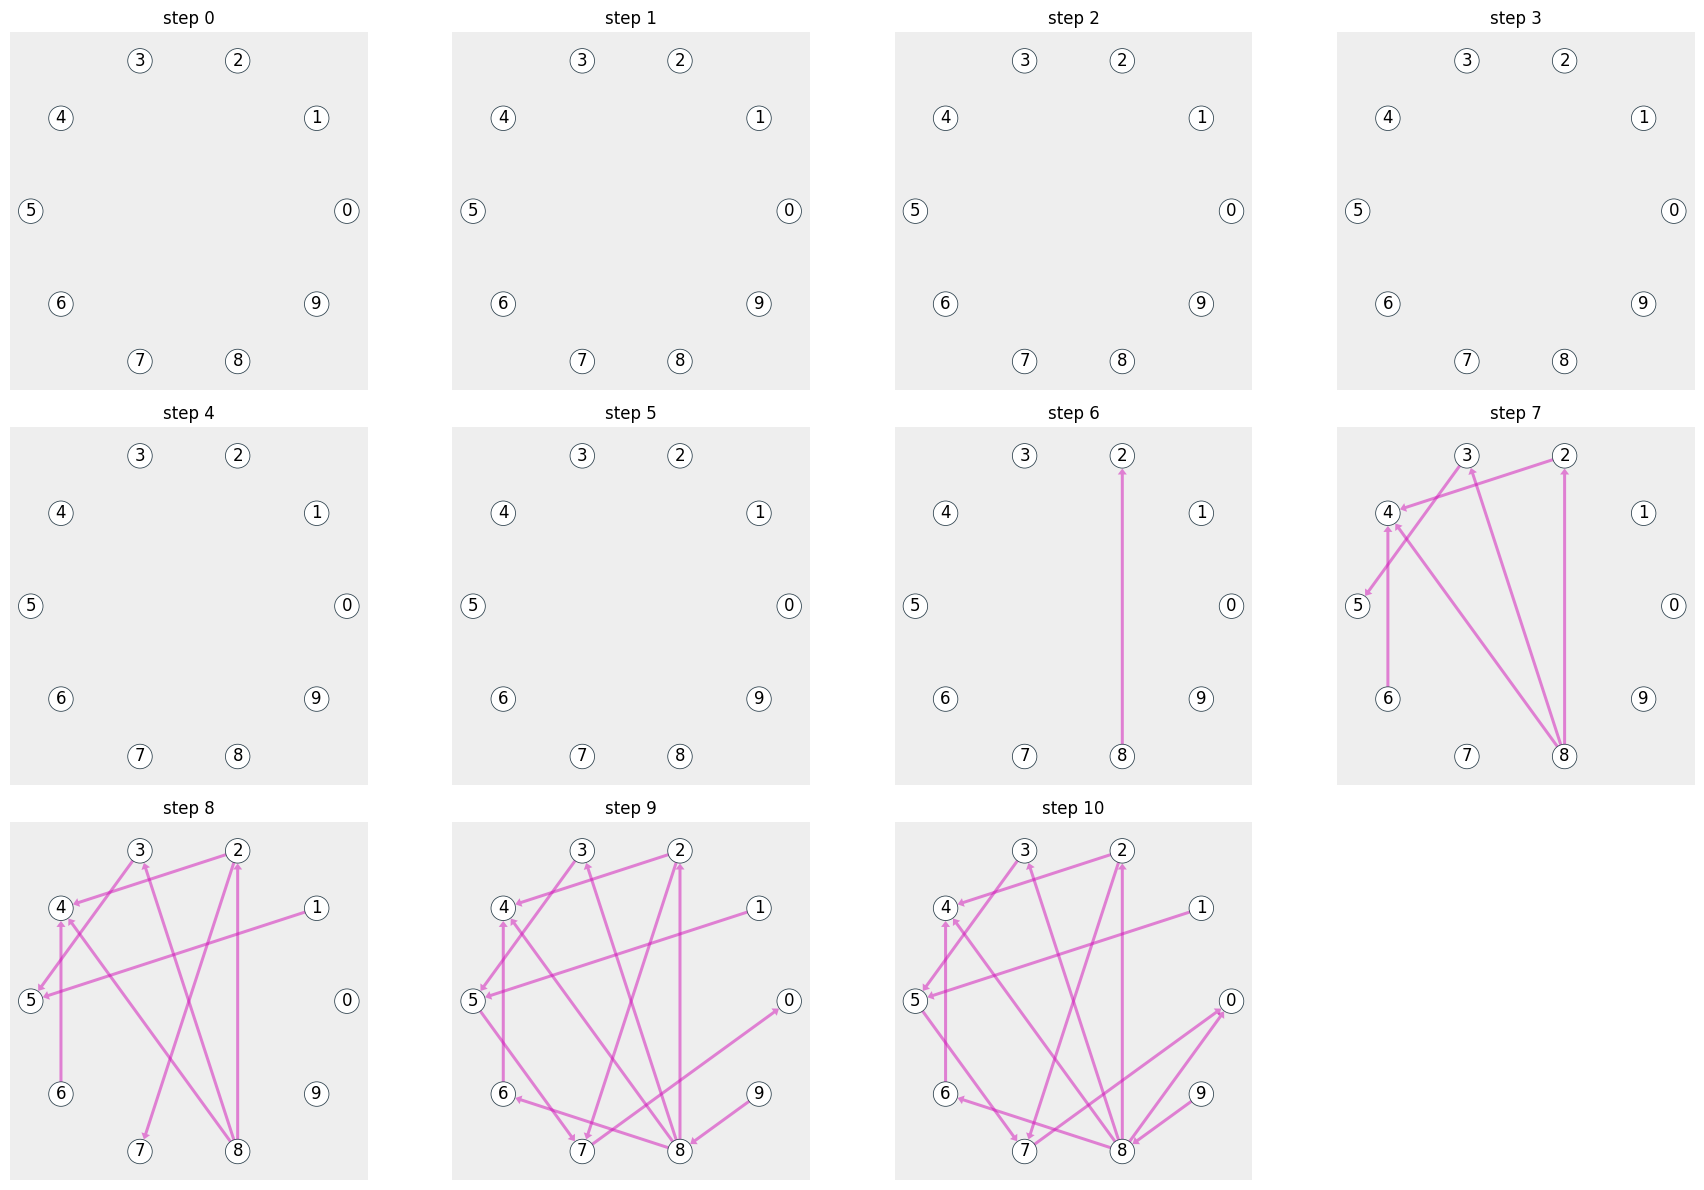

In [9]:
plot_mask = state_history_observer.steps <= 10
plot_steps = state_history_observer.steps[plot_mask]
plot_ownership_matrices = state_history_observer.ownership_matrices[plot_mask]
n_plots = len(plot_steps)
n_rows, n_cols = compute_subplot_shape(n_plots)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax in axes:
    ax.set_facecolor("#eeeeee")
    ax.set_box_aspect(1)

for ax, step, ownership_matrix in zip(
    axes,
    plot_steps,
    plot_ownership_matrices,
    strict=False,
):
    directed_graph = build_ownership_graph(ownership_matrix)
    Graph(
        graph=directed_graph,
        node_layout=fixed_layout,
        node_shape="o",
        node_size=8,
        node_labels={node_id: str(node_id) for node_id in directed_graph.nodes},
        node_label_fontdict=dict(size=12, fontweight="normal"),
        edge_layout="straight",
        edge_width=1.9,
        edge_color="#d111b7",
        edge_label_fontdict=dict(
            size=12,
            fontweight="normal",
            color="b",
            bbox=dict(
                boxstyle="round", ec=(1.0, 1.0, 1.0), fc=(1.0, 1.0, 1.0), alpha=0.9
            ),
        ),
        arrows=True,
        ax=ax,
    )
    ax.set_title(f"step {step}")

for ax in axes[n_plots:]:
    ax.remove()

fig.tight_layout()
plt.show()


## Density across the replay


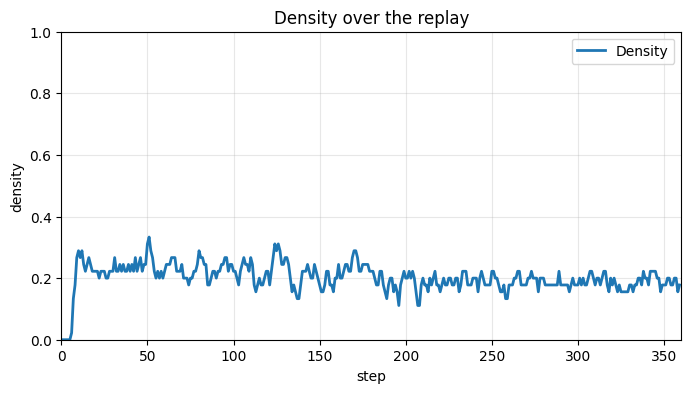

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(
    density_observer.steps,
    density_observer.densities,
    linewidth=2,
    color="#1f77b4",
    label=density_observer.label,
)
plt.xlabel(density_observer.x_label)
plt.ylabel(density_observer.y_label)
plt.ylim(density_observer.y_min, density_observer.y_max)
plt.xlim(0, density_observer.steps[-1] + 1)
plt.title(f"{density_observer.label} over the replay")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
